<div dir="rtl">

# کارگاه جلسه ۱۸ — بیش‌برازش و اعتبارسنجی متقابل

این دفترچه ابزارهایی را تمرین می‌کند که در جزوه فقط به‌صورت مفهومی آمده‌اند. هر بخش مستقل است و کتابخانه‌های لازم خودش را فراخوانی می‌کند. نوشتن این کدها در امتحان پرسیده نمی‌شود.

1. بیش‌برازش روی داده موجی
2. شبیه‌سازی بایاس و واریانس
3. منحنی یادگیری با `learning_curve`
4. مقایسه پنج بخشی و Leave-One-Out
5. چند معیار هم‌زمان با `cross_validate`
6. گونه‌های اعتبارسنجی متقابل
7. تمرین عملی کلاس و پاسخ‌ها

</div>

<div dir="rtl">

## ۱. بیش‌برازش روی داده موجی

پانزده نقطه آموزش از تابع سینوسی با نویز (انحراف معیار ۰.۳) و ۵۰۰ نقطه جدید می‌سازیم و چندجمله‌ای درجه ۱، ۳ و ۹ را برازش می‌دهیم. اعداد همان جدول جزوه است.

</div>

degree=1  train RMSE=0.421  new-data RMSE=0.525
degree=3  train RMSE=0.179  new-data RMSE=0.316
degree=9  train RMSE=0.168  new-data RMSE=0.632


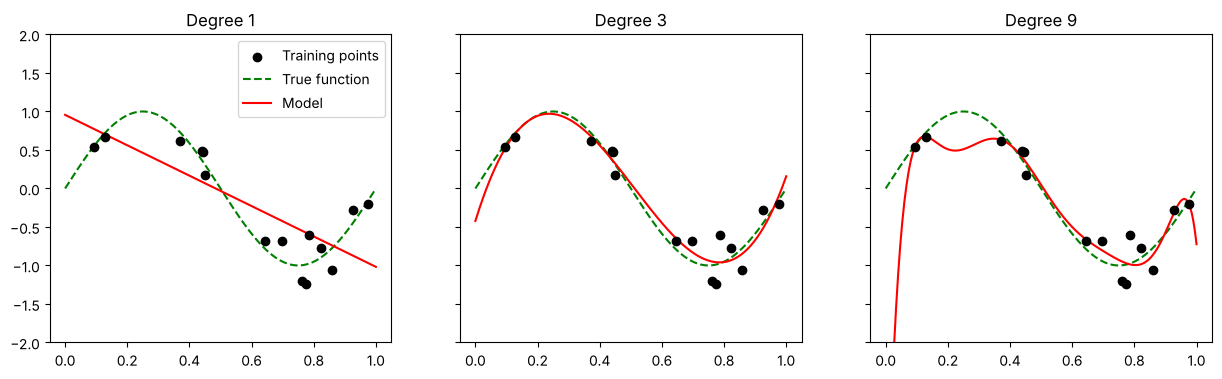

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

rng = np.random.default_rng(42)
x_train = rng.uniform(0, 1, 15)
y_train = np.sin(2 * np.pi * x_train) + rng.normal(0, 0.3, 15)
x_new = rng.uniform(0, 1, 500)
y_new = np.sin(2 * np.pi * x_new) + rng.normal(0, 0.3, 500)

grid = np.linspace(0, 1, 300)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, d in zip(axes, [1, 3, 9]):
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    model.fit(x_train.reshape(-1, 1), y_train)
    tr = root_mean_squared_error(y_train, model.predict(x_train.reshape(-1, 1)))
    te = root_mean_squared_error(y_new, model.predict(x_new.reshape(-1, 1)))
    print(f"degree={d}  train RMSE={tr:.3f}  new-data RMSE={te:.3f}")
    ax.scatter(x_train, y_train, color="black", zorder=3, label="Training points")
    ax.plot(grid, np.sin(2 * np.pi * grid), "g--", label="True function")
    ax.plot(grid, model.predict(grid.reshape(-1, 1)), "r", label="Model")
    ax.set(ylim=(-2, 2), title=f"Degree {d}")
axes[0].legend()
plt.show()

<div dir="rtl">

## ۲. شبیه‌سازی بایاس و واریانس

۲۰۰ مجموعه آموزش مستقل (هر کدام ۲۵ نقطه) می‌سازیم. بایاس به توان دو فاصله میانگین پیش‌بینی‌ها از تابع واقعی و واریانس، پراکندگی پیش‌بینی‌ها میان این ۲۰۰ مدل است.

</div>

In [2]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

x_grid = np.linspace(0.05, 0.95, 50).reshape(-1, 1)
f_grid = np.sin(2 * np.pi * x_grid.ravel())

for d in [1, 3, 5, 7, 9]:
    rng = np.random.default_rng(42)
    preds = []
    for _ in range(200):
        xs = rng.uniform(0, 1, 25)
        ys = np.sin(2 * np.pi * xs) + rng.normal(0, 0.3, 25)
        model = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
        preds.append(model.fit(xs.reshape(-1, 1), ys).predict(x_grid))
    preds = np.array(preds)
    bias2 = ((preds.mean(axis=0) - f_grid) ** 2).mean()
    var = preds.var(axis=0).mean()
    print(f"degree={d}  bias^2={bias2:.4f}  variance={var:.4f}  expected MSE={bias2 + var + 0.09:.3f}")

degree=1  bias^2=0.1526  variance=0.0252  expected MSE=0.268


degree=3  bias^2=0.0032  variance=0.0183  expected MSE=0.112


degree=5  bias^2=0.0002  variance=0.0453  expected MSE=0.136


degree=7  bias^2=0.0016  variance=0.2694  expected MSE=0.361


degree=9  bias^2=0.0178  variance=0.9446  expected MSE=1.052


<div dir="rtl">

## ۳. منحنی یادگیری با learning_curve

روی داده خودروها (مصرف سوخت بر حسب قدرت موتور) منحنی یادگیری درجه ۱ و ۲ را با اعتبارسنجی متقابل ۵ بخشی رسم می‌کنیم.

</div>

degree=1  sizes=[ 25  81 137 193 250]  train=[4.71 4.96 4.84 4.95 4.94]  val=[5.16 4.99 4.98 4.98 4.97]
degree=2  sizes=[ 25  81 137 193 250]  train=[4.05 4.56 4.34 4.42 4.38]  val=[4.92 4.46 4.4  4.4  4.4 ]


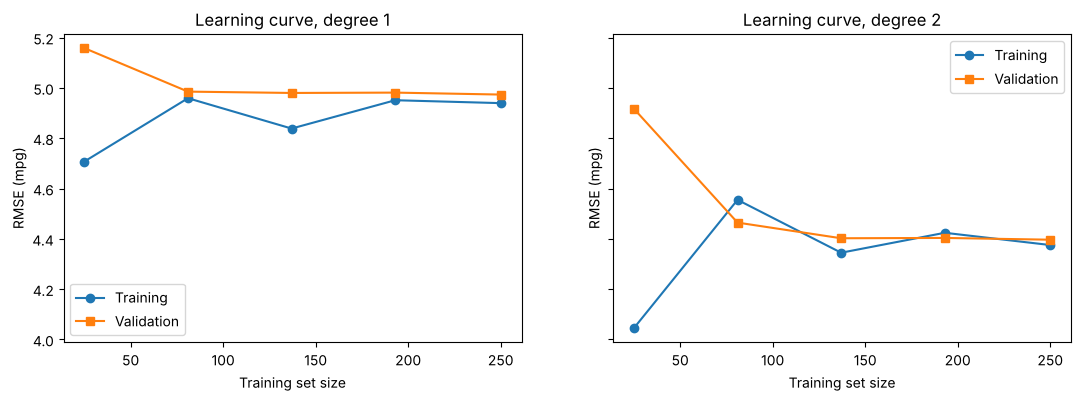

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, learning_curve
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

mpg = sns.load_dataset("mpg").dropna(subset=["horsepower"])
X_train, X_test, y_train, y_test = train_test_split(mpg[["horsepower"]], mpg["mpg"],
                                                    test_size=0.2, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, d in zip(axes, [1, 2]):
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    sizes, tr, va = learning_curve(model, X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 5),
                                   cv=kf, scoring="neg_root_mean_squared_error",
                                   shuffle=True, random_state=42)
    print(f"degree={d}  sizes={sizes}  train={np.round(-tr.mean(axis=1), 2)}  val={np.round(-va.mean(axis=1), 2)}")
    ax.plot(sizes, -tr.mean(axis=1), "o-", label="Training")
    ax.plot(sizes, -va.mean(axis=1), "s-", label="Validation")
    ax.set(xlabel="Training set size", ylabel="RMSE (mpg)", title=f"Learning curve, degree {d}")
    ax.legend()
plt.show()

<div dir="rtl">

## ۴. مقایسه پنج بخشی و Leave-One-Out

در Leave-One-Out هر بخش فقط **یک** نمونه دارد و RMSE یک نمونه همان قدرمطلق خطاست؛ پس میانگین RMSE بخش‌ها در واقع MAE می‌شود. برای مقایسه منصفانه، MSE هر بخش را می‌گیریم و از میانگین آن جذر می‌گیریم.

</div>

In [4]:
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, LeaveOneOut, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

mpg = sns.load_dataset("mpg").dropna(subset=["horsepower"])
X_train, X_test, y_train, y_test = train_test_split(mpg[["horsepower"]], mpg["mpg"],
                                                    test_size=0.2, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for d in [1, 2]:
    model = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    mse_kf = -cross_val_score(model, X_train, y_train, cv=kf, scoring="neg_mean_squared_error")
    mse_loo = -cross_val_score(model, X_train, y_train, cv=LeaveOneOut(), scoring="neg_mean_squared_error")
    print(f"degree={d}  5-fold RMSE={np.sqrt(mse_kf.mean()):.3f}  "
          f"LOO RMSE={np.sqrt(mse_loo.mean()):.3f}  LOO fits={len(mse_loo)}")

degree=1  5-fold RMSE=4.993  LOO RMSE=4.985  LOO fits=313


degree=2  5-fold RMSE=4.428  LOO RMSE=4.418  LOO fits=313


<div dir="rtl">

## ۵. چند معیار هم‌زمان با cross_validate

تابع `cross_validate` چند معیار و (در صورت نیاز) امتیاز آموزش هر دور را هم برمی‌گرداند.

</div>

In [5]:
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

mpg = sns.load_dataset("mpg").dropna(subset=["horsepower"])
X_train, X_test, y_train, y_test = train_test_split(mpg[["horsepower"]], mpg["mpg"],
                                                    test_size=0.2, random_state=42)
model = make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression())
res = cross_validate(model, X_train, y_train, cv=KFold(5, shuffle=True, random_state=42),
                     scoring=["neg_root_mean_squared_error", "r2"], return_train_score=True)
print(f"train RMSE={-res['train_neg_root_mean_squared_error'].mean():.3f}  "
      f"val RMSE={-res['test_neg_root_mean_squared_error'].mean():.3f}  "
      f"val R2={res['test_r2'].mean():.3f}")

train RMSE=4.375  val RMSE=4.397  val R2=0.681


<div dir="rtl">

## ۶. گونه‌های اعتبارسنجی متقابل

روی ده نمونه شماره‌دار (۰ تا ۹) می‌بینیم هر گونه کدام نمونه‌ها را در بخش اعتبارسنجی می‌گذارد.

</div>

In [6]:
import numpy as np
from sklearn.model_selection import KFold, RepeatedKFold, TimeSeriesSplit

X = np.arange(10).reshape(-1, 1)
splitters = {"KFold (no shuffle)": KFold(n_splits=5),
             "KFold (shuffle)":    KFold(n_splits=5, shuffle=True, random_state=42),
             "TimeSeriesSplit":    TimeSeriesSplit(n_splits=4)}
for name, cv in splitters.items():
    print(name)
    for tr, va in cv.split(X):
        print(f"   train={tr}  validation={va}")

print(f"RepeatedKFold: {RepeatedKFold(n_splits=5, n_repeats=3, random_state=42).get_n_splits()} fits in total")

KFold (no shuffle)
   train=[2 3 4 5 6 7 8 9]  validation=[0 1]
   train=[0 1 4 5 6 7 8 9]  validation=[2 3]
   train=[0 1 2 3 6 7 8 9]  validation=[4 5]
   train=[0 1 2 3 4 5 8 9]  validation=[6 7]
   train=[0 1 2 3 4 5 6 7]  validation=[8 9]
KFold (shuffle)
   train=[0 2 3 4 5 6 7 9]  validation=[1 8]
   train=[1 2 3 4 6 7 8 9]  validation=[0 5]
   train=[0 1 3 4 5 6 8 9]  validation=[2 7]
   train=[0 1 2 3 5 6 7 8]  validation=[4 9]
   train=[0 1 2 4 5 7 8 9]  validation=[3 6]
TimeSeriesSplit
   train=[0 1]  validation=[2 3]
   train=[0 1 2 3]  validation=[4 5]
   train=[0 1 2 3 4 5]  validation=[6 7]
   train=[0 1 2 3 4 5 6 7]  validation=[8 9]
RepeatedKFold: 15 fits in total


<div dir="rtl">

## ۷. تمرین عملی کلاس (۲۵ دقیقه)

مصرف سوخت را این بار از **وزن خودرو** پیش‌بینی کنید:

1. سطرهایی را که قدرت موتور آن‌ها گمشده است حذف کنید (تا داده با مثال جزوه یکسان باشد) و داده را با `test_size=0.2` و `random_state=42` تقسیم کنید. داده آزمون را کنار بگذارید.
2. با `validation_curve` و اعتبارسنجی ۵ بخشی (بر زدن با `random_state=42`)، RMSE آموزش و اعتبارسنجی را برای درجه‌های ۱ تا ۸ حساب و رسم کنید.
3. کدام درجه را انتخاب می‌کنید؟ اختلاف بهترین درجه‌ها را با خطای استاندارد مقایسه کنید.
4. برای درجه‌های ۱ و ۲، روش Leave-One-Out را با پنج بخشی مقایسه کنید (مانند بخش ۴).
5. مدل منتخب را روی کل داده آموزش برازش دهید و ضریب تعیین و RMSE آزمون را در کنار RMSE مدل پایه گزارش کنید.
6. (اختیاری) RMSE **آزمون** را برای همه درجه‌ها حساب کنید. اگر درجه را بر اساس داده آزمون انتخاب می‌کردیم، چه اشکالی داشت؟

</div>

In [7]:
# Write your solution here

<div dir="rtl">

### پاسخ تمرین

</div>

train=313  test=79


degree=1  train=4.359  val=4.365 (sd 0.537)
degree=2  train=4.187  val=4.201 (sd 0.503)
degree=3  train=4.186  val=4.215 (sd 0.510)
degree=4  train=4.177  val=4.240 (sd 0.503)
degree=5  train=4.159  val=4.239 (sd 0.499)
degree=6  train=4.149  val=4.257 (sd 0.494)
degree=7  train=4.151  val=4.260 (sd 0.490)
degree=8  train=4.137  val=4.262 (sd 0.512)


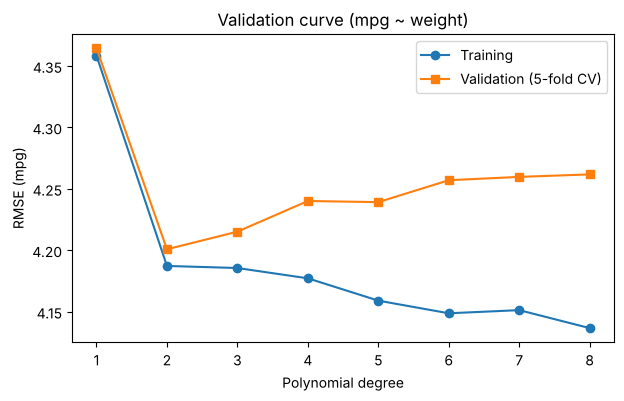

degree=1  5-fold RMSE=4.397  LOO RMSE=4.389


degree=2  5-fold RMSE=4.231  LOO RMSE=4.226
test R2=0.673  RMSE=4.085  baseline RMSE=7.185
degree=1  test RMSE=4.206
degree=2  test RMSE=4.085
degree=3  test RMSE=4.085
degree=4  test RMSE=4.101
degree=5  test RMSE=4.168
degree=6  test RMSE=4.188
degree=7  test RMSE=4.185
degree=8  test RMSE=4.187


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, LeaveOneOut, validation_curve, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

# 1. Data and split
mpg = sns.load_dataset("mpg").dropna(subset=["horsepower"])
X_train, X_test, y_train, y_test = train_test_split(mpg[["weight"]], mpg["mpg"],
                                                    test_size=0.2, random_state=42)
print(f"train={len(X_train)}  test={len(X_test)}")

# 2. Validation curve
model = make_pipeline(PolynomialFeatures(include_bias=False), StandardScaler(), LinearRegression())
kf = KFold(n_splits=5, shuffle=True, random_state=42)
degrees = np.arange(1, 9)
tr, va = validation_curve(model, X_train, y_train, param_name="polynomialfeatures__degree",
                          param_range=degrees, cv=kf, scoring="neg_root_mean_squared_error")
for d, t, v in zip(degrees, -tr.mean(axis=1), -va):
    print(f"degree={d}  train={t:.3f}  val={v.mean():.3f} (sd {v.std():.3f})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(degrees, -tr.mean(axis=1), "o-", label="Training")
ax.plot(degrees, -va.mean(axis=1), "s-", label="Validation (5-fold CV)")
ax.set(xlabel="Polynomial degree", ylabel="RMSE (mpg)", title="Validation curve (mpg ~ weight)")
ax.legend()
plt.show()

# 4. Leave-One-Out vs 5-fold
for d in [1, 2]:
    m = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    mse_kf = -cross_val_score(m, X_train, y_train, cv=kf, scoring="neg_mean_squared_error")
    mse_loo = -cross_val_score(m, X_train, y_train, cv=LeaveOneOut(), scoring="neg_mean_squared_error")
    print(f"degree={d}  5-fold RMSE={np.sqrt(mse_kf.mean()):.3f}  LOO RMSE={np.sqrt(mse_loo.mean()):.3f}")

# 5. Final model, test set used once
model.set_params(polynomialfeatures__degree=2).fit(X_train, y_train)
baseline = DummyRegressor().fit(X_train, y_train)
print(f"test R2={r2_score(y_test, model.predict(X_test)):.3f}  "
      f"RMSE={root_mean_squared_error(y_test, model.predict(X_test)):.3f}  "
      f"baseline RMSE={root_mean_squared_error(y_test, baseline.predict(X_test)):.3f}")

# 6. (Optional) test RMSE for every degree -- for discussion only
for d in degrees:
    model.set_params(polynomialfeatures__degree=d).fit(X_train, y_train)
    print(f"degree={d}  test RMSE={root_mean_squared_error(y_test, model.predict(X_test)):.3f}")

<div dir="rtl">

### پاسخ‌های کلیدی

- پس از حذف سطرهای گمشده ۳۹۲ خودرو داریم: ۳۱۳ آموزش و ۷۹ آزمون.
- RMSE اعتبارسنجی: درجه ۱ حدود **۴.۳۶۵**، درجه ۲ حدود **۴.۲۰۱** (کمینه)، درجه ۳ حدود ۴.۲۱۵ و درجه‌های ۴ تا ۸ بین ۴.۲۴ و ۴.۲۶. انحراف معیار بخش‌ها حدود ۰.۵ و خطای استاندارد حدود ۰.۲۲ است.
- خطای آموزش از حدود ۴.۳۵۹ (درجه ۱) به حدود ۴.۱۳۷ (درجه ۸) کم می‌شود، اما خطای اعتبارسنجی پس از درجه ۲ بهتر نمی‌شود. درجه **۲** انتخاب می‌شود.
- روش Leave-One-Out: درجه ۱ حدود **۴.۳۸۹** و درجه ۲ حدود **۴.۲۲۶**؛ همان نتیجه پنج بخشی (۴.۳۹۷ و ۴.۲۳۱) با حدود ۶۰ برابر آموزش بیشتر.
- مدل درجه ۲ روی آزمون: ضریب تعیین حدود **۰.۶۷۳** و RMSE حدود **۴.۰۹** در برابر RMSE مدل پایه حدود **۷.۱۸**. وزن خودرو پیش‌بین کمی بهتر از قدرت موتور است.
- انتخاب بر اساس آزمون: در این داده هم درجه ۲ (یا ۳ که تقریباً یکسان است) بهترین خطای آزمون را دارد؛ اما اگر درجه را با آزمون انتخاب کنیم، عدد گزارش‌شده دیگر برآورد **بی‌طرفانه** خطای تعمیم نیست، چون آزمون در انتخاب مدل نقش داشته است.

</div>